# ERA5 practical — from resource to production and risk

**Foundations of climate change: basics and impacts — Master's in Energy, M2 — ENERGY-Lab, Université de La Réunion**

The instructions are in the PDF sheet (*TP ERA5 : de la ressource à la production et au risque* / *ERA5 practical: from resource to production and risk*). This notebook only sets things up and gives you a toolbox: **you write the code**, in the cells under each activity heading.

Before you start: *File → Save a copy in Drive*. The archive `ERA5_TP2.zip` must be at the top level of your Google Drive (*My Drive*).

## Set-up (run the three cells, in order)

In [1]:
!pip -q install cartopy netCDF4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 71.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 82.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 53.2 MB/s eta 0:00:00


In [2]:
import os, glob, zipfile

try:                                    # in Colab: connect to Google Drive
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive'
except ImportError:                     # outside Colab: look in the current folder
    ROOT = os.path.abspath('.')

def find_data(root):
    '''Return the folder that contains the ERA5 files (it holds ws100_mon_2000.nc).
    Looks first for an unzipped folder in your Drive, then for the archive ERA5_TP2.zip, which it unzips inside Colab.'''
    for sub in ('data', 'ERA5_TP2', 'ERA5_SWIO/data', '', '*', '*/*'):
        hits = glob.glob(os.path.join(root, sub, 'ws100_mon_2000.nc'))
        if hits:
            return os.path.dirname(hits[0])
    archives = sorted(glob.glob(os.path.join(root, 'ERA5_TP2*.zip')) + glob.glob(os.path.join(root, '*', 'ERA5_TP2*.zip')))
    if archives:
        local = '/content/era5' if os.path.isdir('/content') else os.path.abspath('era5')
        found = glob.glob(f'{local}/**/ws100_mon_2000.nc', recursive=True)
        if not found:
            print('Unzipping', archives[0], '(about one minute)...')
            with zipfile.ZipFile(archives[0]) as z:
                z.extractall(local)
            found = glob.glob(f'{local}/**/ws100_mon_2000.nc', recursive=True)
        if found:
            return os.path.dirname(found[0])
    raise FileNotFoundError(
        'ERA5 files not found. Check that ERA5_TP2.zip is at the top level of your Drive (My Drive), '
        'or write the path yourself: DATA = "/content/drive/MyDrive/<folder>"')

DATA = os.environ.get('ERA5_DATA') or find_data(ROOT)
print('Data folder:', DATA)
print(len(glob.glob(f'{DATA}/*.nc')), 'NetCDF files found')

Mounted at /content/drive
Unzipping /content/drive/MyDrive/ERA5_TP2.zip (about one minute)...
Data folder: /content/era5/ERA5_TP2
35 NetCDF files found


**Toolbox.** `open_monthly(pattern, var=None)` · `season_mean(da, 'DJF')` · `at(da, 'Mauritius')` · `plot_maps(fields, titles, levels, cmap, label)` · `plot_years(values, p50, p90, title, ylabel)` · `wind_cf(speed, k=2)` · `power_curve(v)` · `cf_weibull(v_mean, k)` · `standardise(ds)` · `SITES`. Type `help(plot_maps)` to read the description of a tool.

In [3]:
import math, tempfile, zipfile
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

plt.rcParams.update({'font.size': 12, 'axes.titlesize': 13, 'figure.dpi': 110})

CLIM = ('1991-01-01', '2020-12-31')            # reference period (climate normal)
EXTENT = [-20, 100, -45, 20]                   # map domain: lon west, lon east, lat south, lat north
PROJ = ccrs.PlateCarree()
SEASONS = {'DJF': [12, 1, 2], 'MAM': [3, 4, 5], 'JJA': [6, 7, 8], 'SON': [9, 10, 11]}
SITES = {'La Réunion': (-21.1, 55.5), 'Mauritius': (-20.2, 57.5), 'Antananarivo': (-18.9, 47.5),
         'Toliara': (-23.4, 43.7), 'Maputo': (-26.0, 32.6), 'Johannesburg': (-26.2, 28.0)}

def _done(*things):
    if any(t is ... for t in things):
        raise ValueError('Something is still "...": complete the code first.')

def standardise(ds):
    '''Same names in every file (time, lat, lon) and latitude from south to north.'''
    names = {'valid_time': 'time', 'latitude': 'lat', 'longitude': 'lon'}
    ds = ds.rename({a: b for a, b in names.items() if a in ds.variables})
    ds = ds.drop_vars([c for c in ('number', 'expver') if c in ds.variables])
    return ds.sortby('lat')

def _open_one(path):
    if zipfile.is_zipfile(path):               # the Copernicus server sometimes delivers a zip archive
        folder = os.path.join(tempfile.gettempdir(), os.path.basename(path) + '_unz')
        if not os.path.isdir(folder):
            with zipfile.ZipFile(path) as z:
                z.extractall(folder)
        parts = [standardise(xr.open_dataset(f)) for f in sorted(glob.glob(folder + '/*.nc'))]
        return xr.merge(parts, compat='override')
    return standardise(xr.open_dataset(path))

def open_monthly(pattern, var=None):
    '''Open all the monthly files matching `pattern` and keep the 1991-2020 period.'''
    files = sorted(glob.glob(f'{DATA}/{pattern}'))
    if not files:
        raise FileNotFoundError(f'No file matches {pattern} in {DATA}')
    parts = []
    for f in files:
        ds = _open_one(f)
        name = var or [v for v in ds.data_vars if ds[v].ndim >= 3][0]
        da = ds[name].sel(time=slice(*CLIM))
        if da.sizes['time']:
            parts.append(da.load())
    da = xr.concat(parts, dim='time').sortby('time')
    month_start = pd.to_datetime({'year': da.time.dt.year.values, 'month': da.time.dt.month.values, 'day': 1})
    da = da.assign_coords(time=month_start.values, lat=da.lat.round(3), lon=da.lon.round(3))
    da.attrs = {}
    return da

def season_mean(da, season):
    '''Mean over all the months of a season, all years together.'''
    _done(da)
    return da.sel(time=da.time.dt.month.isin(SEASONS[season])).mean('time')

def at(da, site):
    '''Value at the grid point nearest to a site of the SITES list.'''
    _done(da)
    lat, lon = SITES[site]
    return da.sel(lat=lat, lon=lon, method='nearest')

def plot_maps(fields, titles, levels, cmap, label, arrows=None, extend='both', mark_reunion=True):
    '''One map per field, side by side, same colour scale. Returns the figure.'''
    _done(*fields, levels, cmap, label)
    n = len(fields)
    fig, axes = plt.subplots(1, n, figsize=(7.2 * n, 4.4), subplot_kw={'projection': PROJ},
                             constrained_layout=True, squeeze=False)
    for j, (da, title) in enumerate(zip(fields, titles)):
        ax = axes[0, j]
        ax.set_extent(EXTENT, crs=PROJ)
        filled = ax.contourf(da.lon, da.lat, da.values, levels=levels, cmap=cmap, extend=extend, transform=PROJ)
        ax.coastlines('50m', linewidth=0.8)
        ax.add_feature(cfeature.BORDERS, linewidth=0.3, edgecolor='0.4')
        gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='0.6', alpha=0.5)
        gl.xlocator, gl.ylocator = mticker.MultipleLocator(30), mticker.MultipleLocator(20)
        gl.top_labels = gl.right_labels = False
        gl.left_labels = (j == 0)
        if arrows is not None:                 # arrows = [(u, v), (u, v), ...], one pair per map
            u, v = (a.isel(lat=slice(None, None, 10), lon=slice(None, None, 10)) for a in arrows[j])
            q = ax.quiver(u.lon.values, u.lat.values, u.values, v.values, transform=PROJ,
                          scale=250, width=0.0032, color='0.2')
            ax.quiverkey(q, 0.86, 1.05, 10, '10 m/s', labelpos='E')
        if mark_reunion:
            ax.plot(55.5, -21.1, 'o', ms=7, mfc='none', mec='k', mew=1.5, transform=PROJ)
        ax.set_title(title, loc='left', fontweight='bold')
    fig.colorbar(filled, ax=axes[0, :], shrink=0.85, label=label)
    return fig

def plot_years(values, p50=None, p90=None, title='', ylabel=''):
    '''One point per year, with the P50 and P90 lines if they are given (as on slide 6).'''
    _done(values, p50, p90)
    s = values.to_series() if hasattr(values, 'to_series') else pd.Series(values)
    below = s.values < p90 if p90 is not None else np.zeros(len(s), dtype=bool)
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(s.index, s.values, '-', color='0.75', zorder=1)
    ax.scatter(s.index[~below], s.values[~below], s=48, color='#1f6f78', zorder=2)
    ax.scatter(s.index[below], s.values[below], s=48, color='#a9501c', zorder=2, label='years below P90')
    if p50 is not None:
        ax.axhline(p50, color='#13283b', lw=2, label=f'P50 = {p50:.3g}')
    if p90 is not None:
        ax.axhline(p90, color='#a9501c', lw=2, ls='--', label=f'P90 = {p90:.3g}')
    ax.set_title(title, loc='left', fontweight='bold'); ax.set_ylabel(ylabel); ax.set_xlabel('Year')
    ax.grid(axis='y', alpha=0.3); ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
    return fig

def power_curve(v, v_in=3.0, v_rated=12.0, v_out=25.0):
    '''Generic turbine: fraction of rated power (0 to 1) as a function of wind speed in m/s.'''
    v = np.asarray(v, dtype=float)
    p = np.clip((v**3 - v_in**3) / (v_rated**3 - v_in**3), 0, 1)
    return np.where((v < v_in) | (v > v_out), 0.0, p)

def cf_weibull(v_mean, k=2.0):
    '''Capacity factor when hourly speeds follow a Weibull distribution of mean v_mean and shape k.'''
    c = v_mean / math.gamma(1 + 1 / k)
    speeds = np.linspace(0, 40, 4001)
    pdf = (k / c) * (speeds / c) ** (k - 1) * np.exp(-(speeds / c) ** k)
    return float((power_curve(speeds) * pdf).sum() * (speeds[1] - speeds[0]))

def wind_cf(speed, k=2.0):
    '''Approximate capacity factor from a mean wind speed (Weibull-distributed hourly speeds, shape k).'''
    _done(speed)
    table_v = np.arange(0.1, 25.01, 0.1)
    table_cf = np.array([cf_weibull(v, k) for v in table_v])
    return xr.apply_ufunc(lambda x: np.interp(x, table_v, table_cf), speed)

print('Toolbox ready.')

Toolbox ready.


## Example: how the tools work

Grid point nearest to La Réunion: 5.7 kWh/m²/day


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


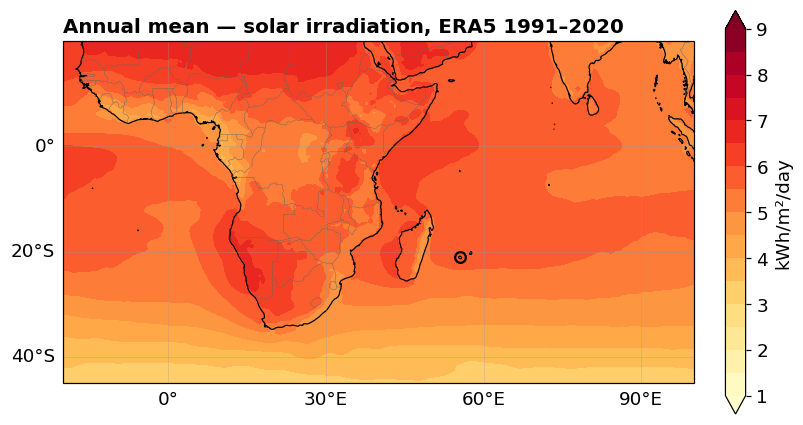

In [4]:
ghi = open_monthly('mon_sl_ssrd_*.nc') / 3.6e6          # J/m2 per day -> kWh/m2/day
ghi_annual = ghi.mean('time')                            # mean over the 360 months
fig = plot_maps([ghi_annual], ['Annual mean — solar irradiation, ERA5 1991–2020'],
                levels=np.arange(1, 9.1, 0.5), cmap='YlOrRd', label='kWh/m²/day')
print('Grid point nearest to La Réunion: %.1f kWh/m²/day' % at(ghi_annual, 'La Réunion'))

## A — Open the files and check them

In [5]:
# >>> CHANGE ICI : ton site (un parmi : 'La Réunion', 'Mauritius', 'Antananarivo', 'Toliara', 'Maputo', 'Johannesburg')
SITE = 'Mauritius'

ghi  = open_monthly('mon_sl_ssrd_*.nc') / 3.6e6            # kWh/m2/jour
wind = open_monthly('ws100_mon_*.nc', var='ws100')          # m/s
temp = open_monthly('mon_sl_t2m_*.nc') - 273.15             # °C
lsm  = standardise(xr.open_dataset(f'{DATA}/mon_sl_lsm_2000.nc'))['lsm'].squeeze()

for name, da, unit in [('Irradiation', ghi, 'kWh/m2/jour'), ('Vent 100 m', wind, 'm/s'), ('Température', temp, '°C')]:
    dlat = float(np.abs(np.diff(da.lat)).mean()); dlon = float(np.abs(np.diff(da.lon)).mean())
    print(f'{name:12s} pas de temps = {da.sizes["time"]}, de {str(da.time.values[0])[:7]} à {str(da.time.values[-1])[:7]}, '
          f'min = {float(da.min()):.2f}, max = {float(da.max()):.2f} {unit}, '
          f'pas de grille = {dlat:.2f}° x {dlon:.2f}° (~{dlat*111:.0f} km)')

Irradiation  pas de temps = 360, de 1991-01 à 2020-12, min = 0.74, max = 9.43 kWh/m2/jour, pas de grille = 0.50° x 0.50° (~56 km)
Vent 100 m   pas de temps = 360, de 1991-01 à 2020-12, min = 0.80, max = 20.63 m/s, pas de grille = 0.50° x 0.50° (~56 km)
Température  pas de temps = 360, de 1991-01 à 2020-12, min = -3.30, max = 39.30 °C, pas de grille = 0.50° x 0.50° (~56 km)


*Notes et réponses :*

| Variable | Pas de temps | Période | Min | Max | Grille |
|---|---|---|---|---|---|
| Irradiation | 360 | 1991-01 → 2020-12 | 0,74 kWh/m²/j | 9,43 kWh/m²/j | 0,5° (~56 km) |
| Vent à 100 m | 360 | 1991-01 → 2020-12 | 0,80 m/s | 20,63 m/s | 0,5° (~56 km) |
| Température | 360 | 1991-01 → 2020-12 | −3,3 °C | 39,3 °C | 0,5° (~56 km) |

- **Valeurs plausibles ?** Oui. L'irradiation reste sous ~9,5 kWh/m²/j (valeur maximale réaliste), le vent moyen mensuel à 100 m ne dépasse 20 m/s que dans les tempêtes du sud de l'océan, et la température va du plateau sud-africain en hiver (−3 °C) au nord chaud du domaine (39 °C). Aucune valeur autour de 290 : la conversion kelvin → °C a bien été faite.
- **Pourquoi 360 pas de temps ?** 30 ans (1991–2020) × 12 mois = 360 moyennes mensuelles.
- **Maille :** 0,5° ≈ 56 km, soit environ deux fois plus grossier que la grille native d'ERA5 (0,25° ≈ 28–31 km, diapo 18).

## B — Seasonal maps of the resource

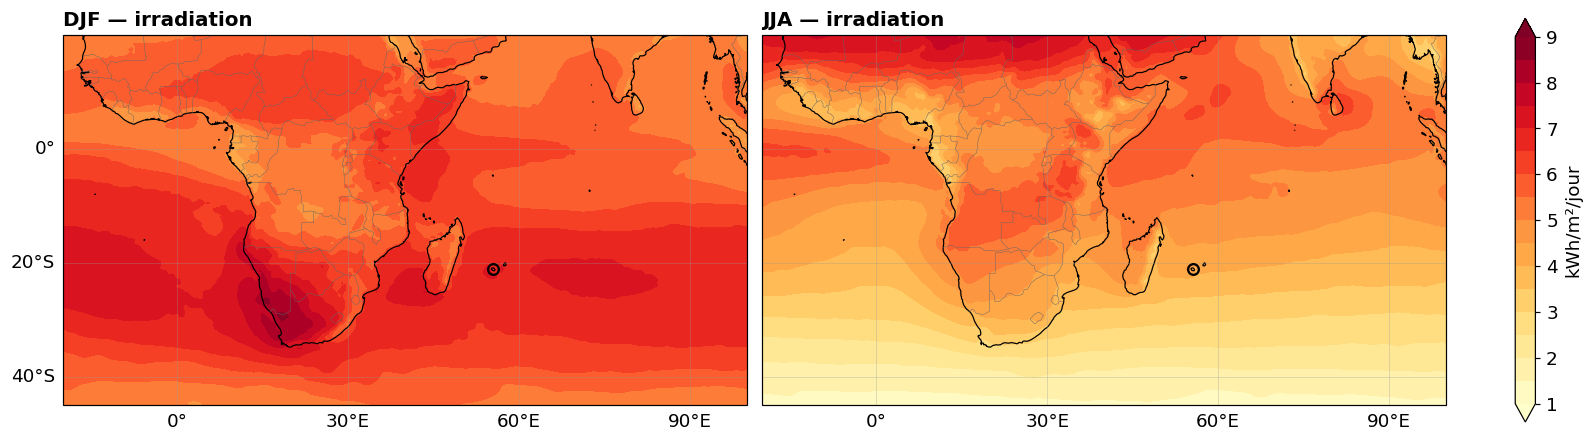

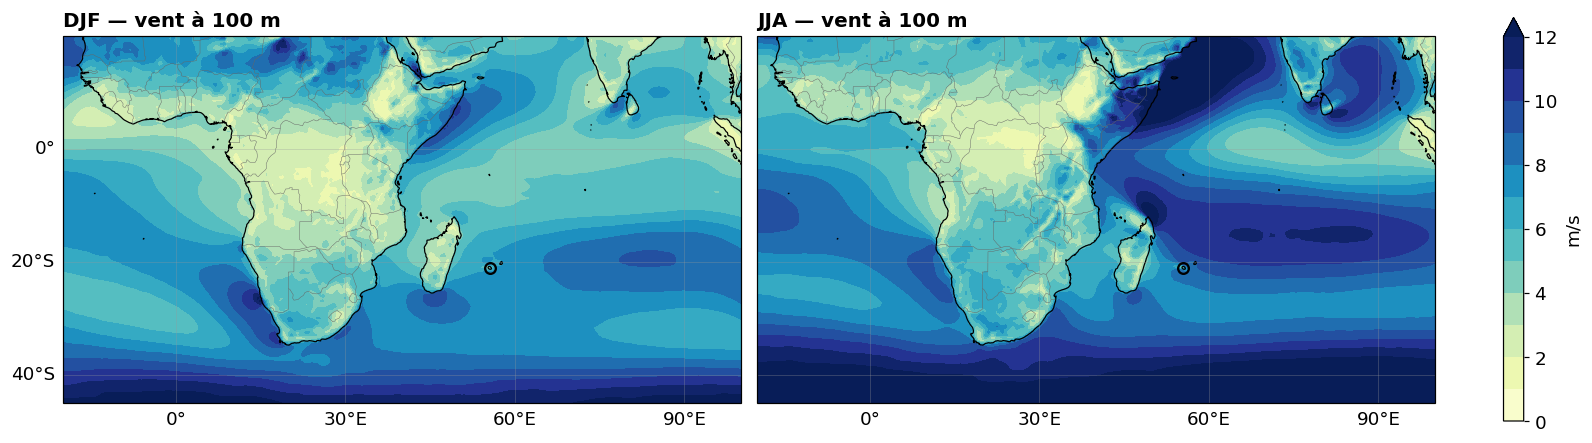

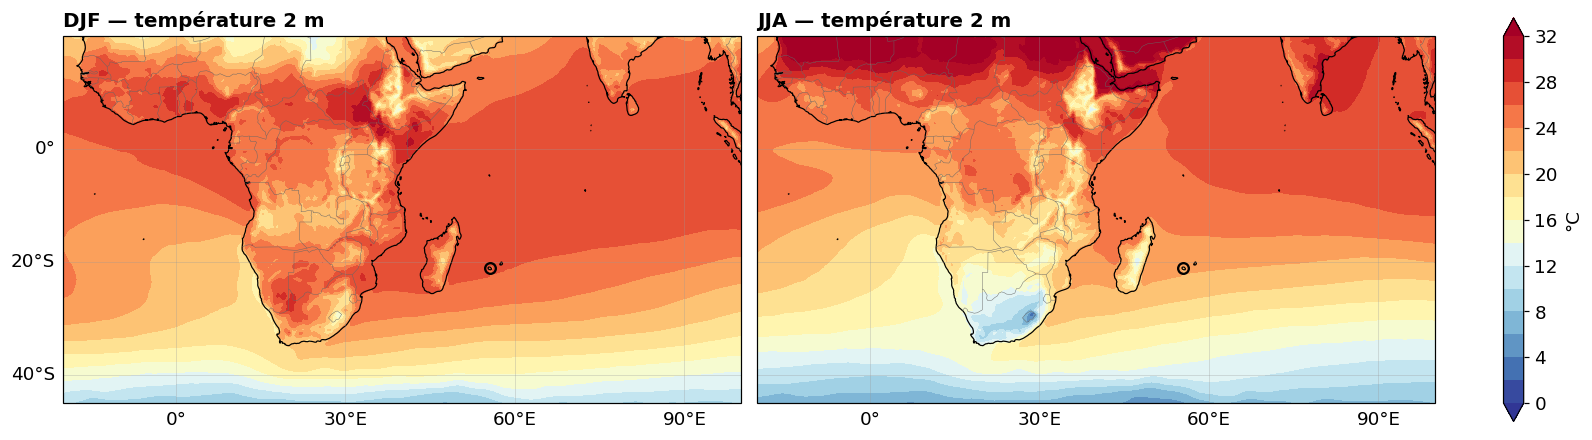

,lat maille,lon maille,lsm (0-1),GHI (kWh/m²/j),Vent 100 m (m/s),T (°C)
Site,,,,,,
La Réunion,-21.0,55.5,0.66,5.71,3.10,21.01
Mauritius,-20.0,57.5,0.09,5.60,7.39,24.30
Antananarivo,-19.0,47.5,1.00,5.28,4.64,18.04
Toliara,-23.5,43.5,0.00,6.05,6.46,25.03
Maputo,-26.0,32.5,0.70,4.87,5.75,23.06
Johannesburg,-26.0,28.0,1.00,5.57,4.35,16.93


            lsm (0-1)  Vent 100 m (m/s)
Site                                   
La Réunion       0.66              3.10
Mauritius        0.09              7.39


In [6]:
# --- Cartes DJF | JJA pour les trois variables ---
fig_ghi = plot_maps([season_mean(ghi, 'DJF'), season_mean(ghi, 'JJA')],
                    ['DJF — irradiation', 'JJA — irradiation'],
                    levels=np.arange(1, 9.1, 0.5), cmap='YlOrRd', label='kWh/m²/jour')

fig_wind = plot_maps([season_mean(wind, 'DJF'), season_mean(wind, 'JJA')],
                     ['DJF — vent à 100 m', 'JJA — vent à 100 m'],
                     levels=np.arange(0, 12.1, 1), cmap='YlGnBu', label='m/s', extend='max')

fig_temp = plot_maps([season_mean(temp, 'DJF'), season_mean(temp, 'JJA')],
                     ['DJF — température 2 m', 'JJA — température 2 m'],
                     levels=np.arange(0, 32.1, 2), cmap='RdYlBu_r', label='°C')
plt.show()

# --- Tableau des six sites ---
ghi_m, wind_m, temp_m = ghi.mean('time'), wind.mean('time'), temp.mean('time')
rows = []
for s in SITES:
    p = at(ghi_m, s)
    rows.append({'Site': s,
                 'lat maille': float(p.lat), 'lon maille': float(p.lon),
                 'lsm (0-1)': float(at(lsm, s)),
                 'GHI (kWh/m²/j)': float(p),
                 'Vent 100 m (m/s)': float(at(wind_m, s)),
                 'T (°C)': float(at(temp_m, s))})
table_sites = pd.DataFrame(rows).set_index('Site').round(2)
display(table_sites)

# --- Question 4 : La Réunion vs Maurice ---
print(table_sites.loc[['La Réunion', 'Mauritius'], ['lsm (0-1)', 'Vent 100 m (m/s)']])

*Notes et réponses :*

**Tableau des six sites** (résultat de la cellule ci-dessus) :

| Site | lat / lon maille | lsm | GHI (kWh/m²/j) | Vent 100 m (m/s) | T (°C) |
|---|---|---|---|---|---|
| La Réunion | −21,0 / 55,5 | 0,66 | 5,71 | 3,10 | 21,0 |
| Maurice | −20,0 / 57,5 | 0,09 | 5,60 | 7,39 | 24,3 |
| Antananarivo | −19,0 / 47,5 | 1,00 | 5,28 | 4,64 | 18,0 |
| Toliara | −23,5 / 43,5 | 0,00 | 6,05 | 6,46 | 25,0 |
| Maputo | −26,0 / 32,5 | 0,70 | 4,87 | 5,75 | 23,1 |
| Johannesburg | −26,0 / 28,0 | 1,00 | 5,57 | 4,35 | 16,9 |

**Question 4 (La Réunion vs Maurice) :** les deux îles sont à 200 km l'une de l'autre dans les mêmes alizés, mais ERA5 donne **3,10 m/s** à La Réunion contre **7,39 m/s** à Maurice. La différence vient de la fraction de terre de la maille : 0,66 à La Réunion (maille surtout terrestre, relief fort lissé sur 55 km) contre 0,09 à Maurice (maille quasi marine, donc vent océanique). **Non**, on n'utiliserait pas la valeur ERA5 pour dimensionner un parc éolien sur la côte réunionnaise : elle est trop faible et ne représente pas le vent réel de la côte. Il faut des mesures locales ou un modèle à plus haute résolution.

**Constats sur les cartes :** 3 par variable (un lieu, une saison, une valeur lue). Pistes de mécanismes du cours : irradiation maximale en DJF (été austral) et minimale en JJA aux latitudes élevées ; alizés de sud-est plus forts en JJA (anticyclone des Mascareignes renforcé) ; contraste terre/mer plus marqué sur la température.

## C — The PV capacity factor

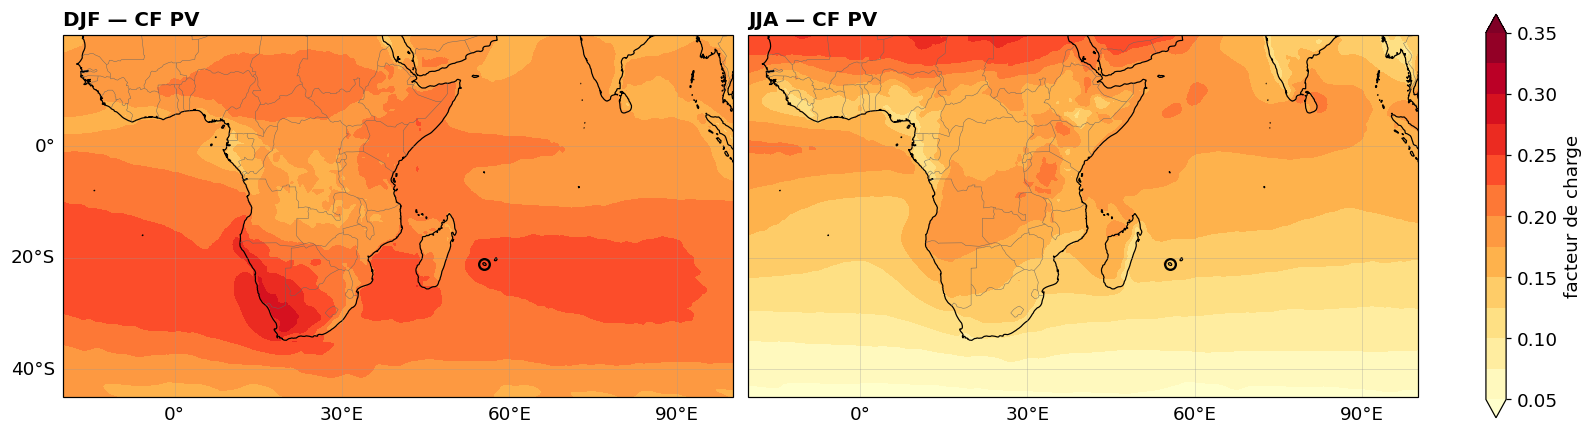

,CF annuel,Heures équivalentes/an
La Réunion,0.190,1668.590
Mauritius,0.187,1634.299
Antananarivo,0.176,1541.484
Toliara,0.202,1766.843
Maputo,0.162,1422.929
Johannesburg,0.186,1626.388


Site : Mauritius
DJF: PR(T) = 0.761 | CF PV avec température = 0.213
MAM: PR(T) = 0.763 | CF PV avec température = 0.162
JJA: PR(T) = 0.774 | CF PV avec température = 0.134
SON: PR(T) = 0.771 | CF PV avec température = 0.206


In [7]:
# --- 1. Facteur de charge PV mensuel (PR = 0.8) ---
cf_pv = 0.8 * ghi / 24

fig_cf = plot_maps([season_mean(cf_pv, 'DJF'), season_mean(cf_pv, 'JJA')],
                   ['DJF — CF PV', 'JJA — CF PV'],
                   levels=np.arange(0.05, 0.36, 0.025), cmap='YlOrRd', label='facteur de charge')
plt.show()

# --- 2. CF annuel et heures équivalentes pour les six sites ---
cf_ann_mean = cf_pv.mean('time')
tab_c = pd.DataFrame({s: {'CF annuel': float(at(cf_ann_mean, s)),
                          'Heures équivalentes/an': float(at(cf_ann_mean, s)) * 8760}
                      for s in SITES}).T.round(3)
display(tab_c)

# --- 4. Option : effet de la température, PR(T) = 0.85 (1 - 0.004 T) ---
pr_T = 0.85 * (1 - 0.004 * temp)
cf_pv_T = pr_T * ghi / 24
print(f'Site : {SITE}')
for s in SEASONS:
    pr_s = float(at(season_mean(pr_T, s), SITE))
    cf_s = float(at(season_mean(cf_pv_T, s), SITE))
    print(f'{s}: PR(T) = {pr_s:.3f} | CF PV avec température = {cf_s:.3f}')

*Notes et réponses :*

**CF annuel et heures équivalentes (six sites) :**

| Site | CF annuel | Heures équivalentes/an |
|---|---|---|
| La Réunion | 0,190 | 1 669 |
| **Maurice** | **0,187** | **1 634** |
| Antananarivo | 0,176 | 1 541 |
| Toliara | 0,202 | 1 767 |
| Maputo | 0,162 | 1 423 |
| Johannesburg | 0,186 | 1 626 |

Maurice : CF annuel 0,187, soit 1 634 heures équivalentes par an, 3e meilleur site sur six. Toliara est le plus productif (0,202), Maputo le moins (0,162).

**3. Pourquoi a-t-on le droit d'appliquer la formule à des moyennes mensuelles ?** Parce que CF_PV ≈ PR × H / 24 est **linéaire** en H : la moyenne d'une fonction linéaire est la fonction de la moyenne (E[a·H] = a·E[H]). On peut donc moyenner l'irradiation avant ou après. Ce n'est pas vrai pour l'éolien, dont la courbe de puissance est non linéaire (activité E).

**4. Option (effet de la température, Maurice) :** PR(T) = 0,761 en DJF, 0,763 en MAM, 0,774 en JJA, 0,771 en SON. C'est donc en **DJF** (été austral, le plus chaud) que la chaleur coûte le plus : le PR y est 1,3 point plus bas qu'en JJA, et le CF PV passe de 0,213 (DJF) à 0,134 (JJA) en tenant compte de la température.

## D — One value per year: P50, P90 and CV

Mauritius : 30 valeurs annuelles
P50 = 162.7 GWh | P90 = 160.2 GWh | CV = 1.75 %


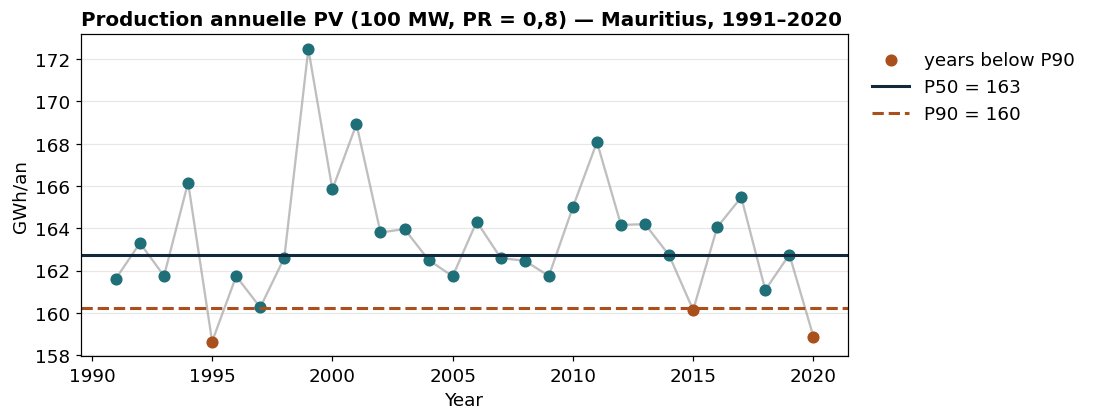

Années sous le P90 : [1995, 2015, 2020] → 3 année(s)
P90 (percentile) = 160.2 GWh | P90 (règle P50 x (1 - 1,28 CV)) = 159.1 GWh


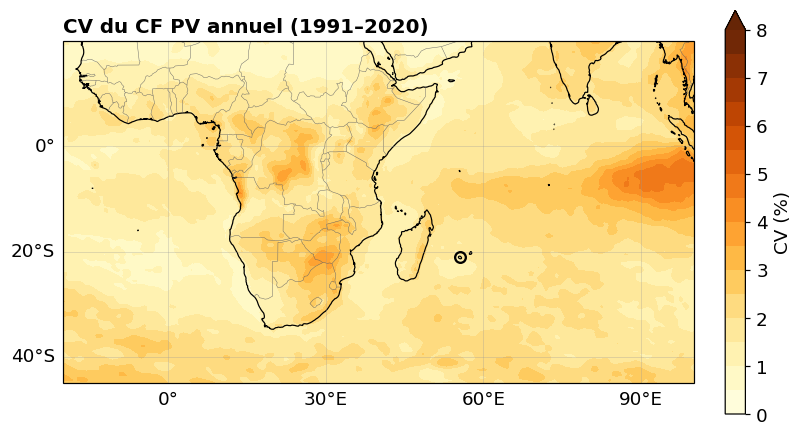

CV le plus faible : 0.5 % | le plus fort : 4.92 %


In [8]:
# --- 1. Production annuelle d'une centrale PV de 100 MW (GWh), 1991-2020 ---
cf_year = cf_pv.groupby('time.year').mean('time')      # un CF par an
e = cf_year * 876                                      # GWh pour 100 MW
e_site = at(e, SITE)
print(f'{SITE} : {e_site.sizes["year"]} valeurs annuelles')

# --- 2. P50, P90 (= 10e centile !), CV ---
p50 = float(np.percentile(e_site, 50))
p90 = float(np.percentile(e_site, 10))
cv  = float(e_site.std('year') / e_site.mean('year') * 100)
print(f'P50 = {p50:.1f} GWh | P90 = {p90:.1f} GWh | CV = {cv:.2f} %')

fig_d = plot_years(e_site, p50, p90,
                   title=f'Production annuelle PV (100 MW, PR = 0,8) — {SITE}, 1991–2020',
                   ylabel='GWh/an')
fig_d.savefig('figure_P50_P90.png', dpi=200, bbox_inches='tight')
plt.show()

# --- 3. Années sous le P90 + règle P50 x (1 - 1.28 CV) ---
below = e_site.where(e_site < p90, drop=True)
print('Années sous le P90 :', [int(y) for y in below.year.values], '→', len(below), 'année(s)')
p90_rule = p50 * (1 - 1.28 * cv / 100)
print(f'P90 (percentile) = {p90:.1f} GWh | P90 (règle P50 x (1 - 1,28 CV)) = {p90_rule:.1f} GWh')

# --- 4. Carte du CV du CF PV annuel ---
cv_map = cf_year.std('year') / cf_year.mean('year') * 100
fig_cv = plot_maps([cv_map], ['CV du CF PV annuel (1991–2020)'],
                   levels=np.arange(0, 8.1, 0.5), cmap='YlOrBr', label='CV (%)', extend='max')
plt.show()
print('CV le plus faible :', round(float(cv_map.min()), 2), '% | le plus fort :', round(float(cv_map.max()), 2), '%')

*Notes et réponses :*

**Résultats pour Maurice (100 MW, PR = 0,8, 1991–2020) :**
- P50 = **162,7 GWh/an** ; P90 = **160,2 GWh/an** ; CV = **1,75 %**.
- **Années sous le P90 :** 1995, 2015 et 2020 (3 années sur 30, comme attendu pour un 10e centile).
- **Règle P50 × (1 − 1,28 × CV) :** 159,1 GWh, très proche du P90 calculé (160,2 GWh) : l'écart est d'environ 1 GWh, la distribution est proche d'une loi normale.

**Carte du CV du CF PV annuel :** il varie de **0,5 %** (le plus régulier) à **4,92 %** (le moins régulier) sur le domaine. Le CV de Maurice (1,75 %) est donc faible. Repère sur ta carte où se trouvent les deux extrêmes : en général, le solaire est le plus stable dans les zones sèches (Namibie, Kalahari, sud-ouest de Madagascar) et le moins stable là où passent la zone de convergence intertropicale, la mousson ou les cyclones.

## E — If you have time: wind

Vitesse : P50 = 7.40 m/s | P90 = 7.08 m/s | CV = 4.30 %
CF éolien : P50 = 0.324 | P90 = 0.297 | CV = 8.00 %
CV solaire (rappel, activité D) = 1.75 %


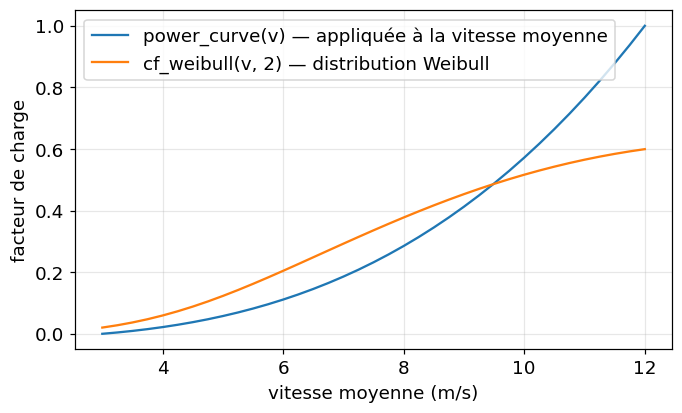

À 7 m/s : power_curve = 0.186 | Weibull = 0.293 | erreur = -0.107 (-37 %)


In [9]:
# --- 1. P50, P90 et CV de la vitesse annuelle moyenne à 100 m ---
wind_year = wind.groupby('time.year').mean('time')
v_site = at(wind_year, SITE)
v50, v90 = float(np.percentile(v_site, 50)), float(np.percentile(v_site, 10))
cv_v = float(v_site.std('year') / v_site.mean('year') * 100)
print(f'Vitesse : P50 = {v50:.2f} m/s | P90 = {v90:.2f} m/s | CV = {cv_v:.2f} %')

# --- 2. Facteur de charge éolien approché, une valeur par année ---
cf_wind = wind_cf(wind)
cf_wind_year = cf_wind.groupby('time.year').mean('time')
w_site = at(cf_wind_year, SITE)
w50, w90 = float(np.percentile(w_site, 50)), float(np.percentile(w_site, 10))
cv_w = float(w_site.std('year') / w_site.mean('year') * 100)
print(f'CF éolien : P50 = {w50:.3f} | P90 = {w90:.3f} | CV = {cv_w:.2f} %')
print(f'CV solaire (rappel, activité D) = {cv:.2f} %')

# --- 3. Courbe de puissance vs CF Weibull ---
vv = np.arange(3, 12.01, 0.25)
fig_pc, ax = plt.subplots(figsize=(7, 4))
ax.plot(vv, power_curve(vv), label='power_curve(v) — appliquée à la vitesse moyenne')
ax.plot(vv, [cf_weibull(v, 2) for v in vv], label='cf_weibull(v, 2) — distribution Weibull')
ax.set_xlabel('vitesse moyenne (m/s)'); ax.set_ylabel('facteur de charge')
ax.grid(alpha=0.3); ax.legend()
plt.show()
a, b = float(power_curve(7.0)), cf_weibull(7.0, 2)
print(f'À 7 m/s : power_curve = {a:.3f} | Weibull = {b:.3f} | erreur = {a - b:+.3f} ({(a - b) / b * 100:+.0f} %)')

*Notes et réponses :*

**Maurice :**
- Vitesse annuelle à 100 m : P50 = 7,40 m/s, P90 = 7,08 m/s, CV = **4,3 %**.
- CF éolien approché : P50 = 0,324, P90 = 0,297, CV = **8,0 %**.
- Rappel du CV solaire : **1,75 %**.

Le CV du CF éolien (8,0 %) est près de 2 fois celui de la vitesse (4,3 %) : comme la puissance varie environ comme v³ entre 3 et 12 m/s, une petite variation de vitesse est amplifiée en production. Le solaire (1,75 %) est environ 4,5 fois plus régulier que l'éolien d'une année à l'autre.

**Fiabilité :** la maille ERA5 de Maurice est presque entièrement marine (fraction de terre 0,09, vent de 7,39 m/s en moyenne), donc le vent ERA5 y est bien plus représentatif qu'à La Réunion. Mais le CF éolien reste approché : un vrai facteur de charge demande des vitesses horaires.

**3. Courbe de puissance vs Weibull :** à 7 m/s, `power_curve` donne 0,186 et `cf_weibull(7, 2)` donne 0,293. Appliquer la courbe de puissance à la vitesse moyenne **sous-estime donc la production de 37 %** (erreur de −0,107 en facteur de charge). Raison : la vitesse réelle fluctue autour de la moyenne et l'énergie dépend de toute la distribution des vitesses, pas seulement de sa moyenne.

## F — If you have time: mixing wind and solar

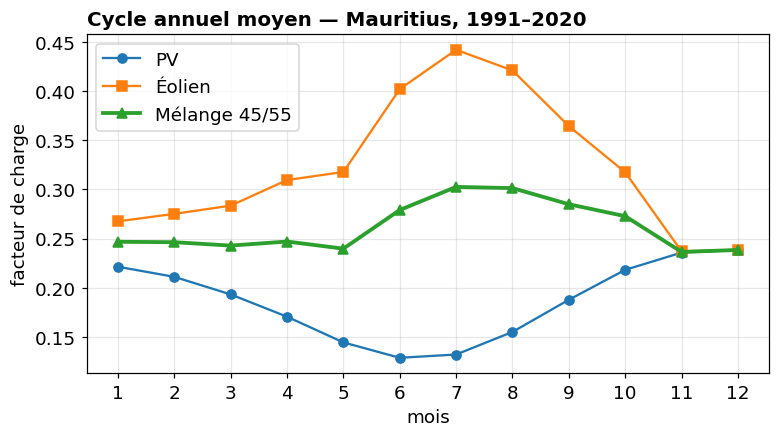

Corrélation entre les cycles PV et éolien : -0.85


,CF moyen,mois faible / moyenne,CV annuel (%),P90/P50
PV,0.187,0.692,1.751,0.985
Éolien,0.323,0.734,8.002,0.918
Mélange,0.262,0.904,5.327,0.946


In [10]:
# --- 1. Mélange 45 % PV / 55 % éolien ---
alpha = 0.45
cf_mix = alpha * cf_pv + (1 - alpha) * cf_wind

# --- 2. Cycle annuel moyen des trois productions sur le site ---
cyc_pv  = at(cf_pv,   SITE).groupby('time.month').mean('time')
cyc_w   = at(cf_wind, SITE).groupby('time.month').mean('time')
cyc_mix = at(cf_mix,  SITE).groupby('time.month').mean('time')

fig_f, ax = plt.subplots(figsize=(8, 4))
ax.plot(cyc_pv.month, cyc_pv, 'o-', label='PV')
ax.plot(cyc_w.month, cyc_w, 's-', label='Éolien')
ax.plot(cyc_mix.month, cyc_mix, '^-', lw=2.5, label='Mélange 45/55')
ax.set_xticks(range(1, 13)); ax.set_xlabel('mois'); ax.set_ylabel('facteur de charge')
ax.set_title(f'Cycle annuel moyen — {SITE}, 1991–2020', loc='left', fontweight='bold')
ax.grid(alpha=0.3); ax.legend()
plt.show()
print('Corrélation entre les cycles PV et éolien : %.2f' % float(xr.corr(cyc_pv, cyc_w)))

# --- 3. Tableau comparatif ---
def stats(cf_monthly):
    cyc = at(cf_monthly, SITE).groupby('time.month').mean('time')
    ann = at(cf_monthly.groupby('time.year').mean('time'), SITE)
    return {'CF moyen': float(ann.mean()),
            'mois faible / moyenne': float(cyc.min() / cyc.mean()),
            'CV annuel (%)': float(ann.std('year') / ann.mean('year') * 100),
            'P90/P50': float(np.percentile(ann, 10) / np.percentile(ann, 50))}

tab_f = pd.DataFrame({'PV': stats(cf_pv), 'Éolien': stats(cf_wind), 'Mélange': stats(cf_mix)}).T.round(3)
display(tab_f)

*Notes et réponses :*

| | CF moyen | Mois faible / moyenne | CV annuel | P90/P50 |
|---|---|---|---|---|
| PV | 0,187 | 0,692 | 1,75 % | 0,985 |
| Éolien | 0,323 | 0,734 | 8,00 % | 0,918 |
| Mélange 45/55 | 0,262 | 0,904 | 5,33 % | 0,946 |

La corrélation entre les cycles annuels PV et éolien est de **−0,85** : à Maurice, le vent est nettement plus fort quand le soleil est plus faible (alizés renforcés en hiver austral).

**Ce que gagne le mélange :** un cycle annuel beaucoup plus plat. Le mois le plus faible passe de 0,69 (PV) ou 0,73 (éolien) à **0,90** de la moyenne annuelle, grâce à la forte corrélation négative. Le CV annuel (5,3 %) est aussi meilleur que celui de l'éolien seul (8,0 %), et le P90/P50 (0,946) est meilleur que celui de l'éolien seul (0,918).

**Ce qu'il perd :** le facteur de charge moyen (0,262) est inférieur à celui de l'éolien seul (0,323). Il est aussi moins régulier d'une année à l'autre que le PV seul (CV de 5,3 % contre 1,75 %, P90/P50 de 0,946 contre 0,985). Le mélange réduit donc le risque saisonnier, pas le risque d'une année à l'autre.

## G — What you hand in

In [11]:
# --- 1. Figure à rendre (déjà enregistrée en D) ---
fig_d.savefig('figure_P50_P90.png', dpi=200, bbox_inches='tight')

# --- 2. Légende + constats chiffrés + interprétation, générés à partir de tes résultats ---
years_below = ', '.join(str(int(y)) for y in below.year.values)
caption = (f"Production annuelle d'une centrale photovoltaïque de 100 MW (PR = 0,8) à {SITE}, en GWh/an, "
           f"de 1991 à 2020, calculée à partir de l'irradiation mensuelle ERA5 (grille 0,5°). "
           f"Chaque point est une année ; la ligne pleine marque le P50 ({p50:.1f} GWh) et les tirets le P90 "
           f"({p90:.1f} GWh) ; les points orange sont les années sous le P90 ({years_below}).")
print('LÉGENDE :\n', caption, '\n')

print('CONSTATS :')
print(f"1. Solaire : P50 = {p50:.1f} GWh, P90 = {p90:.1f} GWh, CV = {cv:.1f} %.")
try:
    print(f"2. Vent : vitesse annuelle à 100 m P50 = {v50:.2f} m/s (CV = {cv_v:.1f} %) ; "
          f"CF éolien approché P50 = {w50:.3f}, CV = {cv_w:.1f} %.")
    print(f"3. Mélange 45/55 : CF moyen = {tab_f.loc['Mélange','CF moyen']:.3f}, "
          f"CV annuel = {tab_f.loc['Mélange','CV annuel (%)']:.1f} % (PV : {tab_f.loc['PV','CV annuel (%)']:.1f} %, "
          f"éolien : {tab_f.loc['Éolien','CV annuel (%)']:.1f} %).")
except NameError:
    print('(exécute E et F pour obtenir les constats vent et mélange)')

risque = 'faible' if cv < 3 else 'modéré' if cv < 6 else 'élevé'
print(f"\nINTERPRÉTATION :\nÀ {SITE}, une centrale PV de 100 MW produit au moins {p90:.0f} GWh neuf années sur dix, "
      f"soit {p90 / p50 * 100:.0f} % du P50, avec {cv:.1f} % de variation d'une année à l'autre : "
      f"le risque climatique est {risque}, donc le P90 peut servir de base pour le financement.")

# Pour télécharger l'image depuis Colab :
try:
    from google.colab import files
    files.download('figure_P50_P90.png')
except ImportError:
    pass

LÉGENDE :
 Production annuelle d'une centrale photovoltaïque de 100 MW (PR = 0,8) à Mauritius, en GWh/an, de 1991 à 2020, calculée à partir de l'irradiation mensuelle ERA5 (grille 0,5°). Chaque point est une année ; la ligne pleine marque le P50 (162.7 GWh) et les tirets le P90 (160.2 GWh) ; les points orange sont les années sous le P90 (1995, 2015, 2020). 

CONSTATS :
1. Solaire : P50 = 162.7 GWh, P90 = 160.2 GWh, CV = 1.8 %.
2. Vent : vitesse annuelle à 100 m P50 = 7.40 m/s (CV = 4.3 %) ; CF éolien approché P50 = 0.324, CV = 8.0 %.
3. Mélange 45/55 : CF moyen = 0.262, CV annuel = 5.3 % (PV : 1.8 %, éolien : 8.0 %).

INTERPRÉTATION :
À Mauritius, une centrale PV de 100 MW produit au moins 160 GWh neuf années sur dix, soit 98 % du P50, avec 1.8 % de variation d'une année à l'autre : le risque climatique est faible, donc le P90 peut servir de base pour le financement.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

*Notes et réponses :*

**Légende (à copier avec la figure) :**
Production annuelle d'une centrale photovoltaïque de 100 MW (PR = 0,8) à Maurice, en GWh/an, de 1991 à 2020, calculée à partir de l'irradiation mensuelle ERA5 (grille 0,5°). Chaque point est une année ; la ligne pleine marque le P50 (162,7 GWh) et les tirets le P90 (160,2 GWh) ; les points orange sont les années sous le P90 (1995, 2015, 2020).

**Trois constats chiffrés :**
1. **Solaire :** P50 = 162,7 GWh, P90 = 160,2 GWh, CV = 1,8 %.
2. **Vent :** vitesse annuelle à 100 m P50 = 7,40 m/s (CV 4,3 %) ; CF éolien approché P50 = 0,324, CV = 8,0 %.
3. **Mélange 45/55 :** CF moyen 0,262 et CV annuel 5,3 %, contre 0,187 et 1,8 % pour le PV seul ; le mois le plus faible passe de 0,69 à 0,90 de la moyenne annuelle.

**Interprétation pour un porteur de projet :**
À Maurice, une centrale PV de 100 MW produit au moins 160 GWh neuf années sur dix, soit 98 % du P50, avec seulement 1,8 % de variation d'une année à l'autre : le risque climatique est faible, donc le P90 peut servir de base pour le financement.